In [153]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mstats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import accuracy_score, log_loss, roc_auc_score, f1_score, recall_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

In [154]:
df = pd.read_csv("../data/JFF_formatted_public_release_labels.csv", encoding="latin1")
df.shape

(18429, 153)

In [155]:
# Remove missing job satisfaction responses
df_clean = df.dropna(subset=["Q4"]).copy()

# Convert Q4 responses into numeric satisfaction ratings
df_clean["Q4_Numeric"] = pd.to_numeric(
    df_clean["Q4"].astype(str).str.extract(r"^(\d+)")[0],
    errors="coerce"
)

# Keep valid satisfaction ratings (0-10)
df_clean = df_clean[
    df_clean["Q4_Numeric"].between(0, 10)
].copy()

# Binary target:
# 1 = Highly satisfied (8-10)
# 0 = Not highly satisfied (0-7)
y_binary = (df_clean["Q4_Numeric"] >= 8).astype(int)

print("Cleaned dataset shape:", df_clean.shape)
print("\nTarget distribution:")
print(y_binary.value_counts())

Cleaned dataset shape: (18381, 154)

Target distribution:
Q4_Numeric
0    10736
1     7645
Name: count, dtype: int64


In [156]:
# Baseline: Demographics and employment characteristics
baseline_features = [
    "Q20",            # Weekly working hours
    "Q40",            # Monthly earnings
    "Q14",            # Job tenure
    "Q65",            # Gender
    "Q9",             # Employment type
    "Q8",             # Organization size
    "Q17",            # Days worked per week
    "MARITAL_STATUS", # Marital status
    "EDUCATION",      # Education
    "Q51",            # Age
    "REGION"          # Region
]

# Job quality features
job_quality_features = [
    "Q33A", "Q33B", "Q33C", "Q33D", "Q33E",
    "Q33F", "Q33G", "Q33H", "Q33I", "Q33J",
    "Q55"
]

# Expanded model: Baseline + Job Quality
expanded_features = list(dict.fromkeys(baseline_features + job_quality_features))

print("Baseline features:", len(baseline_features))
print("Expanded features:", len(expanded_features))

Baseline features: 11
Expanded features: 22


In [157]:
# Create feature matrix
X = df_clean[expanded_features].copy()

# Replace nonresponse categories with NaN
X = X.replace(["No response", "Not sure", "Not applicable", " "], np.nan)

# Convert numeric features
X["Q20"] = pd.to_numeric(X["Q20"], errors="coerce")

X["Q17"] = pd.to_numeric(X["Q17"].astype(str).str.extract(r"^(\d+)")[0], errors="coerce")

X["Q51"] = pd.to_numeric(X["Q51"], errors="coerce")

# Split data before preprocessing
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y_binary, test_size=0.33, random_state=1234, stratify=y_binary )

print("Training shape:", X_train_raw.shape)
print("Testing shape:", X_test_raw.shape)

Training shape: (12315, 22)
Testing shape: (6066, 22)


In [158]:
def preprocess_features(X_train_raw, X_test_raw, features):

    # Select features for this model
    X_train = X_train_raw[features].copy()
    X_test = X_test_raw[features].copy()

    # Numeric features
    numeric_cols = [
        col for col in ["Q20", "Q17", "Q51"]
        if col in features
    ]

    # Fill numeric missing values using training medians
    for col in numeric_cols:
        median_value = X_train[col].median()

        if pd.isna(median_value):
            median_value = 0

        X_train[col] = X_train[col].fillna(median_value)
        X_test[col] = X_test[col].fillna(median_value)

    # Categorical features
    categorical_cols = [
        col for col in X_train.columns
        if col not in numeric_cols
    ]

    # Fill categorical missing values
    for col in categorical_cols:
        X_train[col] = (X_train[col].astype("object").fillna("Missing"))
        X_test[col] = (X_test[col].astype("object").fillna("Missing"))

    # One-hot encode categorical features
    X_train = pd.get_dummies(X_train, columns=categorical_cols, drop_first=False, dtype=float)

    X_test = pd.get_dummies(X_test, columns=categorical_cols, drop_first=False, dtype=float)

    # Align test columns with training columns
    X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

    # Save feature names before scaling
    feature_names = X_train.columns.tolist()

    # Scale using training data only
    scaler = StandardScaler()

    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    return X_train, X_test, feature_names

In [159]:
def train_test_LR(X_train, y_train, X_test, y_test, c=1):

    # Initialize and train model
    model = LogisticRegression(C=c, max_iter=2000, random_state=42)

    model.fit(X_train, y_train)

    # Predictions
    probability_predictions = model.predict_proba(X_test)
    class_label_predictions = model.predict(X_test)

    # Evaluation metrics
    l_loss = log_loss(y_test, probability_predictions)
    acc_score = accuracy_score(y_test, class_label_predictions)
    auc_score = roc_auc_score(y_test, probability_predictions[:, 1])
    f1 = f1_score(y_test, class_label_predictions)
    recall = recall_score(y_test, class_label_predictions)

    return {"model": model, "log_loss": l_loss, "accuracy": acc_score, "roc_auc": auc_score,
        "f1": f1, "recall": recall, "predictions": class_label_predictions,
        "probabilities": probability_predictions[:, 1]
    }

In [160]:
# Preprocess baseline features
X_train_baseline, X_test_baseline, baseline_names = preprocess_features(X_train_raw,
    X_test_raw, baseline_features)

# Train baseline model
baseline_results = train_test_LR(X_train_baseline, y_train, X_test_baseline, y_test)

# Preprocess expanded features
X_train_expanded, X_test_expanded, expanded_names = preprocess_features(X_train_raw,
    X_test_raw, expanded_features)

# Train expanded model
expanded_results = train_test_LR(X_train_expanded, y_train, X_test_expanded, y_test)

print("Baseline model trained successfully.")
print("Expanded model trained successfully.")

Baseline model trained successfully.
Expanded model trained successfully.


In [161]:
# Compare baseline and expanded model performance
model_comparison = pd.DataFrame({
    "Model": ["Baseline", "Baseline + Job Quality"],
    "Accuracy": [baseline_results["accuracy"], expanded_results["accuracy"]],
    "ROC-AUC": [baseline_results["roc_auc"], expanded_results["roc_auc"]],
    "F1 Score": [baseline_results["f1"], expanded_results["f1"]],
    "Recall": [baseline_results["recall"], expanded_results["recall"]],
    "Log Loss": [baseline_results["log_loss"], expanded_results["log_loss"]]
})

display(model_comparison.round(4))

,Model,Accuracy,ROC-AUC,F1 Score,Recall,Log Loss
0,Baseline,0.6274,0.6532,0.4562,0.3757,0.6432
1,Baseline + Job Quality,0.7572,0.8307,0.7069,0.7039,0.4974


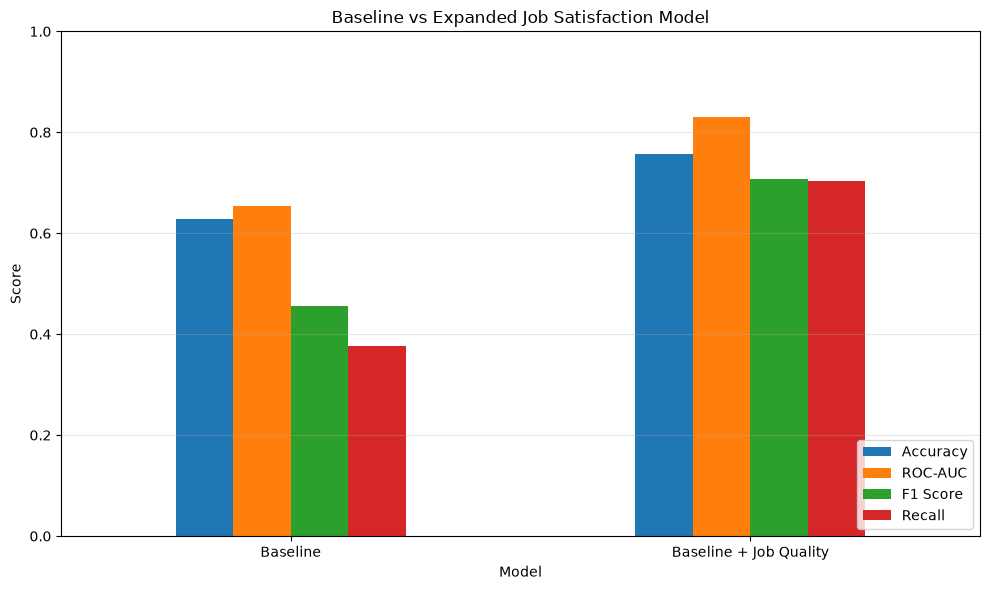

In [162]:
# Plot model comparison
model_comparison.set_index("Model")[
    ["Accuracy", "ROC-AUC", "F1 Score", "Recall"]].plot(kind="bar", figsize=(10, 6), rot=0)

plt.title("Baseline vs Expanded Job Satisfaction Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

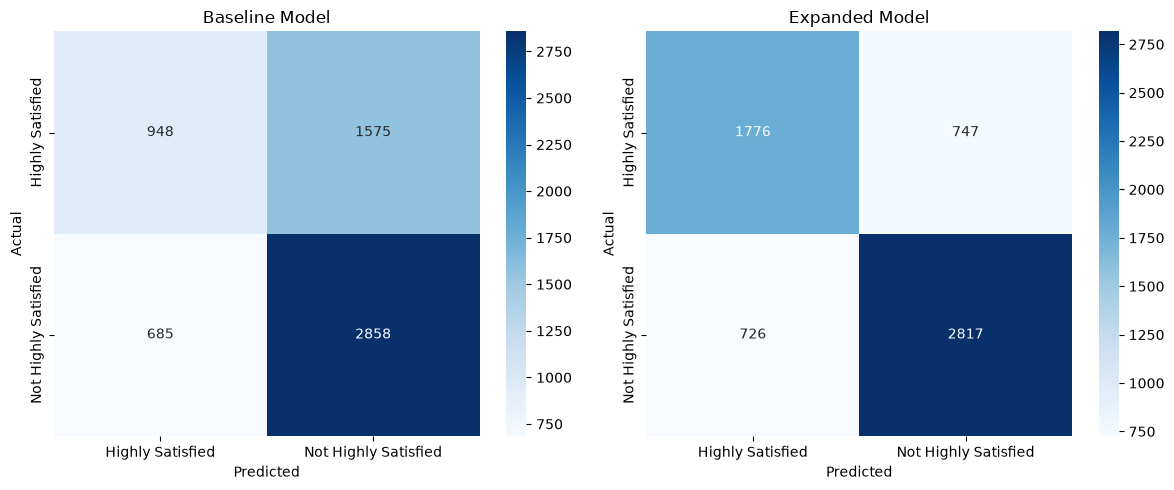

In [163]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

results_list = [("Baseline Model", baseline_results), ("Expanded Model", expanded_results)]

for ax, (title, results) in zip(axes, results_list):
    cm = confusion_matrix(y_test, results["predictions"], labels=[1, 0])

    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["Highly Satisfied", "Not Highly Satisfied"],
        yticklabels=["Highly Satisfied", "Not Highly Satisfied"],
        ax=ax)

    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [164]:
# Get trained expanded model
model = expanded_results["model"]

# Create dataframe of feature coefficients
coef_df = pd.DataFrame({"Feature": expanded_names, "Coefficient": model.coef_[0]})

# Calculate absolute coefficient values
coef_df["Absolute_Coefficient"] = (coef_df["Coefficient"].abs())

# Sort by absolute coefficient magnitude
coef_df = coef_df.sort_values(by="Absolute_Coefficient", ascending=False)

# Display top 5 encoded features
top_5_features = coef_df.head(5)

print("Top 5 Influential Features:")
display(top_5_features)

Top 5 Influential Features:


,Feature,Coefficient,Absolute_Coefficient
95,Q33G_Strongly agree,0.408500,0.408500
96,Q33G_Strongly disagree,-0.334959,0.334959
94,Q33G_Somewhat disagree,-0.277573,0.277573
2,Q51,0.273215,0.273215
107,Q33I_Strongly agree,0.240018,0.240018


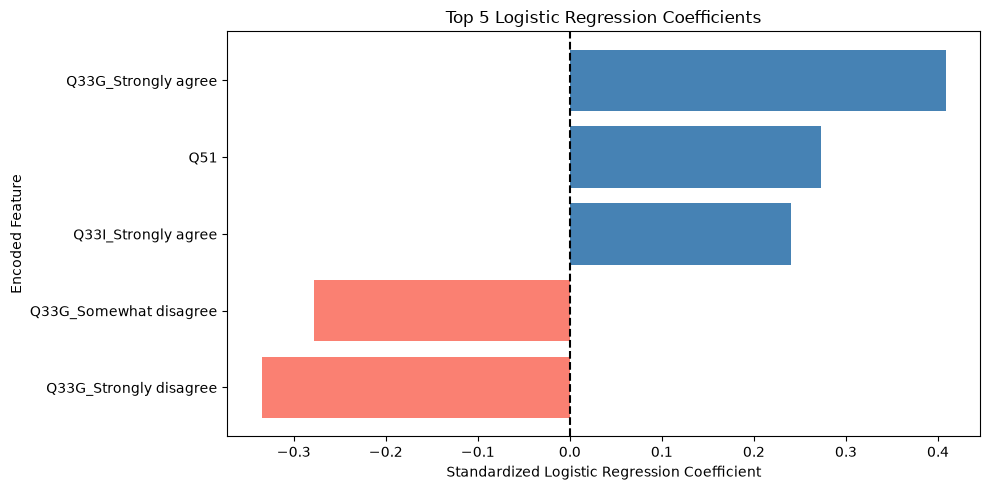

In [165]:
# Sort for horizontal bar chart
top_5_plot = top_5_features.sort_values(by="Coefficient")

plt.figure(figsize=(10, 5))

colors = [
    "steelblue" if coef > 0 else "salmon"
    for coef in top_5_plot["Coefficient"]
]

plt.barh(top_5_plot["Feature"], top_5_plot["Coefficient"], color=colors)

plt.axvline(0, color="black", linestyle="--")

plt.xlabel("Standardized Logistic Regression Coefficient")
plt.ylabel("Encoded Feature")
plt.title("Top 5 Logistic Regression Coefficients")

plt.tight_layout()
plt.show()

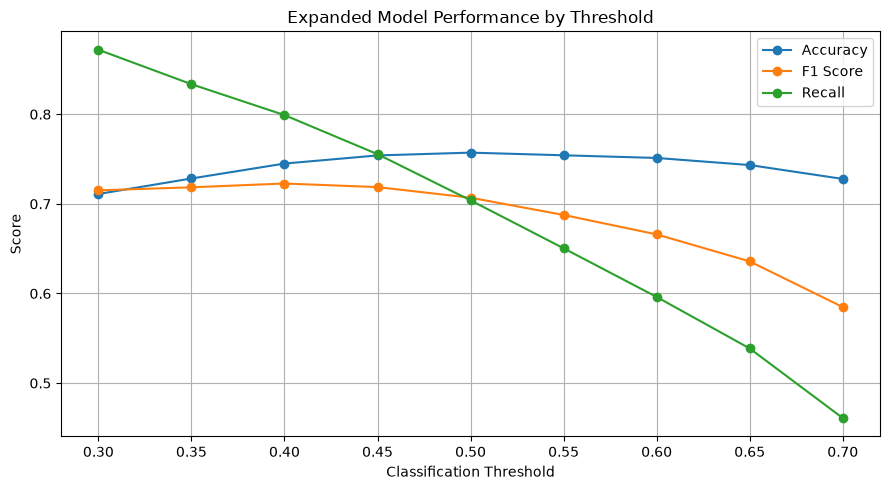

In [166]:
# Predicted probabilities from expanded model
y_prob = expanded_results["probabilities"]

# Test different classification thresholds
thresholds = np.arange(0.30, 0.71, 0.05)

accuracy_scores = []
f1_scores = []
recall_scores = []

for threshold in thresholds:
    y_pred = (y_prob >= threshold).astype(int)

    accuracy_scores.append(accuracy_score(y_test, y_pred))

    f1_scores.append(f1_score(y_test, y_pred))

    recall_scores.append(recall_score(y_test, y_pred))

# Plot threshold performance
plt.figure(figsize=(9, 5))

plt.plot(thresholds, accuracy_scores, marker="o", label="Accuracy")

plt.plot(thresholds, f1_scores, marker="o", label="F1 Score")

plt.plot(thresholds, recall_scores, marker="o", label="Recall")

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Expanded Model Performance by Threshold")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

                   Feature  Coefficient  Absolute_Coefficient
68     Q33G_Strongly agree     0.602172              0.602172
76     Q33I_Strongly agree     0.288475              0.288475
2                      Q51     0.270640              0.270640
64     Q33F_Strongly agree     0.269040              0.269040
69  Q33G_Strongly disagree    -0.240429              0.240429
66     Q33G_Somewhat agree     0.226297              0.226297
52     Q33C_Strongly agree     0.192924              0.192924
67  Q33G_Somewhat disagree    -0.171380              0.171380
77  Q33I_Strongly disagree    -0.167021              0.167021
65  Q33F_Strongly disagree    -0.146753              0.146753
75  Q33I_Somewhat disagree    -0.138579              0.138579
63  Q33F_Somewhat disagree    -0.129644              0.129644
56     Q33D_Strongly agree    -0.123728              0.123728
74     Q33I_Somewhat agree     0.122959              0.122959
44     Q33A_Strongly agree     0.119640              0.119640
25      

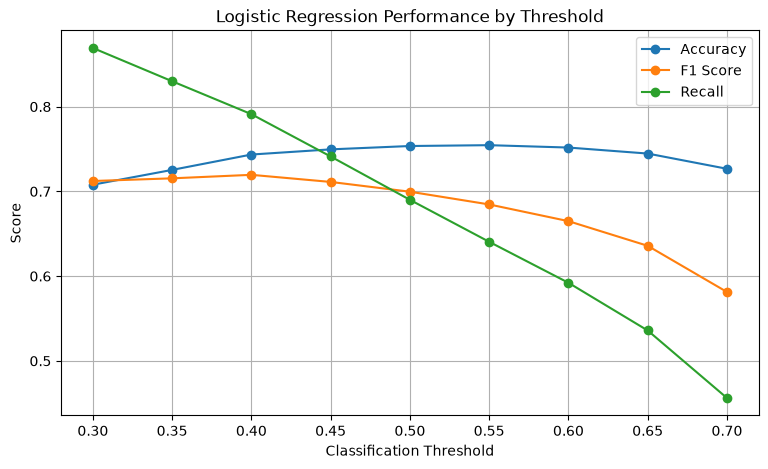

In [167]:
model = LogisticRegression(C=1, max_iter=2000, random_state=42)

model.fit(X_train, y_train)

# Create dataframe of feature coefficients
coef_df = pd.DataFrame({"Feature": feature_names, "Coefficient": model.coef_[0]})

# Calculate absolute coefficients
coef_df["Absolute_Coefficient"] = coef_df["Coefficient"].abs()

# Sort by importance
coef_df = coef_df.sort_values(by="Absolute_Coefficient", ascending=False)

print(coef_df.head(20))
# Get predicted probabilities for highly satisfied
y_prob = model.predict_proba(X_test)[:, 1]

# Test different thresholds
thresholds = np.arange(0.30, 0.71, 0.05)

accuracy_scores = []
f1_scores = []
recall_scores = []

for threshold in thresholds:
    y_pred = (y_prob >= threshold).astype(int)
    accuracy_scores.append(accuracy_score(y_test, y_pred))
    f1_scores.append(f1_score(y_test, y_pred))
    recall_scores.append(recall_score(y_test, y_pred))

plt.figure(figsize=(9, 5))
plt.plot(thresholds, accuracy_scores, marker='o', label='Accuracy')
plt.plot(thresholds, f1_scores, marker='o', label='F1 Score')
plt.plot(thresholds, recall_scores, marker='o', label='Recall')

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Logistic Regression Performance by Threshold")
plt.legend()
plt.grid(True)
plt.show()